# Solutions: Bayesian Networks from Knowledge Graphs

These exercises accompany the notebook *Bayesian Networks from Knowledge Graphs*. They use the same HALD graph and the same network, with variables Gene $G$, Neighbour gene $N$, Disease $Z$ and Metabolite $L$ and the factorisation

$$P(G,N,Z,L)=P(G)\,P(N\vert G)\,P(Z\vert G,N)\,P(L\vert Z).$$

Each exercise says what you are asked to do, and has a part to do **by hand** and a part to do **in code**. In this solutions notebook the missing lines are filled in, and each solution is followed by a discussion of the output.

| Exercise | Skill | Time |
|:--|:--|:--|
| 1 | Estimating CPTs from a graph by hand, on a toy graph | 15 min |
| 2 | Choosing state spaces; leakage from the withheld set | 10 min |
| 3 | Choosing smoothing constants *without* peeking at the test set | 15 min |
| 4 | Conditional independence by marginalising the joint distribution | 10 min |
| 5 | Explaining a recommendation with SPARQL | 10 min |

## Setup

The three code cells below are copied, unchanged, from the main notebook. They load HALD with Owlready2, extract the links with SPARQL, build the count matrices, split off the withheld links, build the network (`model`), and define the inference function `posterior_genes`, the function `recommend` and the evaluation function `rank_metrics`. Run them once, in order. (They take about ten seconds.) The file `HALD.rdf` must be in the same folder as this notebook.

In [1]:
import collections
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from owlready2 import World

HALD_FILE = "HALD.rdf"          # the RDF/XML file, in the same folder as this notebook
SEED = 2024                     # seed for the train/withheld split
METAB = ["Lipid", "Carbohydrate"]   # the node classes that we treat as "metabolites"

world = World()                                                   # a fresh quadstore, so that re-running this cell starts clean
onto = world.get_ontology(Path(HALD_FILE).resolve().as_uri()).load()
print(f"{len(list(onto.individuals())):,} individuals, {len(list(onto.object_properties())):,} object properties, "
      f"{len(list(onto.classes()))} classes")

PREFIXES = "PREFIX h: <http://www.dummy.info/new.owl#>\n"

def sparql(query):
    """Run a SPARQL query against the loaded graph; returns a list of rows."""
    return list(world.sparql(PREFIXES + query))

12,256 individuals, 3,058 object properties, 10 classes


In [2]:
def link_table(types_a, types_b):
    """Distinct pairs (a, b), a of a class in types_a and b of a class in types_b, linked by ANY relation in
    EITHER direction. The UNION makes the query symmetric, which collapses the relation vocabulary to a single
    'linked' relation and ignores direction."""
    values = lambda var, types: f"VALUES {var} {{ " + " ".join("h:" + t for t in types) + " }"
    query = f"""SELECT DISTINCT ?a ?b WHERE {{
        {values('?type_a', types_a)} {values('?type_b', types_b)}
        ?a a ?type_a . ?b a ?type_b .
        {{ ?a ?rel ?b }} UNION {{ ?b ?rel ?a }}
        ?rel a owl:ObjectProperty .
        FILTER (?a != ?b) }}"""
    out = pd.DataFrame([(a.name, b.name) for a, b in sparql(query)], columns=["source", "target"])
    return out.sort_values(["source", "target"]).reset_index(drop=True)

gene_disease = link_table(["Gene"], ["Disease"])
gene_gene = link_table(["Gene"], ["Gene"])                      # symmetric, so both directions are present
disease_metabolite = link_table(["Disease"], METAB)
gene_metabolite = link_table(["Gene"], METAB)                   # NOT used by the model: kept for a later check

print(f"gene-disease: {len(gene_disease):,}   gene-gene (both directions): {len(gene_gene):,}   disease-metabolite: {len(disease_metabolite):,}")

# Universe: genes with at least one disease link; diseases linked to at least two genes
# (so that a disease can lose one edge to the withheld set and still have evidence left).
n_links = gene_disease.groupby("target").size()          # genes linked to each disease
diseases = sorted(n_links[n_links >= 2].index)
gene_disease = gene_disease[gene_disease.target.isin(diseases)]
genes = sorted(gene_disease.source.unique())
g_idx = {g: i for i, g in enumerate(genes)}
z_idx = {z: i for i, z in enumerate(diseases)}
nG, nZ = len(genes), len(diseases)

# Withhold a random 20% of the gene-disease links. Sort first, so the split depends only on SEED.
pairs = np.array([(g_idx[g], z_idx[z]) for g, z in zip(gene_disease.source, gene_disease.target)])
pairs = pairs[np.lexsort((pairs[:, 1], pairs[:, 0]))]
perm = np.random.default_rng(SEED).permutation(len(pairs))
n_held = int(0.2 * len(pairs))
held, train = pairs[perm[:n_held]], pairs[perm[n_held:]]
print(f"{nG:,} genes, {nZ:,} diseases;  {len(train):,} training links, {len(held):,} withheld links")

# Count matrices (sparse). Rows are indexed by the first letter(s) of the name, as in the rest of the notes.
CZG = sp.csr_matrix((np.ones(len(train)), (train[:, 1], train[:, 0])), shape=(nZ, nG))   # CZG[z, g] = 1 if training link g-z

gg = [(g_idx[a], g_idx[b]) for a, b in zip(gene_gene.source, gene_gene.target) if a in g_idx and b in g_idx]
NB = sp.csr_matrix((np.ones(len(gg)), tuple(zip(*gg))), shape=(nG, nG))                  # NB[n, g] = 1 if genes n and g are linked
NB.data[:] = 1

# Metabolites (lipids and carbohydrates): keep the K most-linked metabolites (among universe diseases) and merge the rest into 'other'.
dm = disease_metabolite[disease_metabolite.source.isin(diseases)]
K = 20
top_met = dm.target.value_counts().head(K).index.tolist()
metabolites = top_met + ["other"]
l_idx = {l: i for i, l in enumerate(metabolites)}
CLZ = sp.lil_matrix((len(metabolites), nZ))                                                # CLZ[l, z] = 1 if disease z has metabolite m
for z, l in zip(dm.source, dm.target):
    CLZ[l_idx.get(l, K), z_idx[z]] = 1
CLZ = CLZ.tocsr()
nL = len(metabolites)

summary = pd.DataFrame({
    "relation": ["gene-disease (training)", "gene-gene", "disease-metabolite (kept)"],
    "number of links": [CZG.nnz, NB.nnz // 2, CLZ.nnz],
    "used for": ["P(G), P(Z|G,N)", "P(N|G), P(Z|G,N)", "P(L|Z)"]})
print(f"{K} named metabolites cover {dm.target.isin(top_met).sum()} of {len(dm)} disease-metabolite links")

gene-disease: 9,454   gene-gene (both directions): 5,566   disease-metabolite: 2,481
2,324 genes, 699 diseases;  7,228 training links, 1,806 withheld links
20 named metabolites cover 1017 of 2087 disease-metabolite links


In [3]:
def build_model(CZG, NB, CLZ, lam=0.5, b=1.0, c=1.0):
    """Estimate the four CPTs from count matrices. Nothing larger than (diseases x genes) is ever stored.

    CZG[z, g]  training links between disease z and gene g      NB[n, g]  links between genes n and g
    CLZ[l, z]  links between metabolite l and disease z
    lam        weight given to the neighbour genes when a gene already has training links of its own
    b, c       add-b / add-c (Laplace-style) smoothing for P(Z|N) and P(L|Z)
    """
    nZ, nG = CZG.shape
    nL = CLZ.shape[0]
    d = np.asarray(CZG.sum(axis=0)).ravel()                      # training links per gene
    nz = np.asarray(CZG.sum(axis=1)).ravel()                     # training links per disease
    PZ0 = (nz + 1) / (nz.sum() + nZ)                             # P(Z): smoothed marginal

    PG = (d + 1) / (d.sum() + nG)                                # P(G): add-one smoothed share of links

    deg = np.asarray(NB.sum(axis=0)).ravel()                     # P(N|G=g): uniform over the neighbours of g ...
    PN_G = NB @ sp.diags(1 / np.maximum(deg, 1))                 # (sparse, columns sum to 1)
    PN = np.asarray(NB.sum(axis=1)).ravel() + 0.0                # ... and for a gene with no neighbours, the marginal
    PN = PN / PN.sum() if PN.sum() > 0 else np.full(nG, 1 / nG)  #     distribution of neighbours

    # P(Z|N): what a gene n says about diseases, from its own training links, smoothed towards P(Z)
    PZ_N = (CZG.toarray() + b * PZ0[:, None]) / (d[None, :] + b)

    # Mediator part of P(Z|G) = sum_n P(n|g) P(Z|n): a sparse-times-dense product
    via_N = np.asarray((PZ_N @ PN_G))                            # (nZ x nG)
    iso = deg == 0
    via_N[:, iso] = (PZ_N @ PN)[:, None]                         # genes with no neighbours use the marginal

    lam_g = np.where(d > 0, lam, 1.0)                            # a gene with no training links relies on N entirely
    own = CZG.toarray() / np.maximum(d, 1)[None, :]              # empirical P(Z|g) from the gene's own links
    PZ_G = (1 - lam_g) * own + lam_g * via_N                     # P(Z|G): P(Z|G,N) marginalised over N (see text)

    PL_Z = (CLZ.toarray() + c * ((np.asarray(CLZ.sum(axis=1)).ravel() + 1) / (CLZ.sum() + nL))[:, None])
    PL_Z = PL_Z / PL_Z.sum(axis=0, keepdims=True)                # P(L|Z): smoothed towards the marginal P(L)
    return dict(PG=PG, PN_G=PN_G, PN=PN, PZ_N=PZ_N, PZ_G=PZ_G, PL_Z=PL_Z, PZ0=PZ0, d=d, lam_g=lam_g, own=own, deg=deg)

model = build_model(CZG, NB, CLZ)
print("P(G) sums to", model["PG"].sum().round(6),
      "| every column of P(Z|G) sums to 1:", np.allclose(model["PZ_G"].sum(axis=0), 1),
      "| every column of P(L|Z) sums to 1:", np.allclose(model["PL_Z"].sum(axis=0), 1))

def likelihood(model, z):
    """P(Z=z | G=g) for every gene g at once: one row of the (diseases x genes) matrix P(Z|G)."""
    return model["PZ_G"][z]

def posterior_genes(model, z, uniform_prior=False):
    """P(G | Z=z) by Bayes' rule: proportional to P(G) P(z|G). Exact, and uses only the stored pieces."""
    prior = np.full(len(model["PG"]), 1 / len(model["PG"])) if uniform_prior else model["PG"]
    post = prior * likelihood(model, z)
    return post / post.sum()

def diseases_for_gene(model, g):
    """P(Z | G=g): a column of P(Z|G), with no inference needed."""
    return model["PZ_G"][:, g]

# Training-link lookup, used to exclude links that are already known
known = CZG.toarray() > 0
held_by_disease = collections.defaultdict(list)
for g, z in held:
    held_by_disease[z].append(g)

def recommend(z, k=5):
    p = posterior_genes(model, z)
    p = np.where(known[z], -np.inf, p)            # exclude genes already linked to z in the training graph
    top = np.argsort(-p)[:k]
    return pd.DataFrame({"gene": [genes[g] for g in top], "P(G|Z=z)": p[top],
                         "withheld link?": [g in held_by_disease[z] for g in top]})



def rank_metrics(scores, pairs, by="gene", known_mat=None):
    """Rank the withheld link for each (g, z) pair. scores[z, g] is a score for every candidate.
    by='gene': candidates are genes, for the given disease (query: P(G|Z=z)); by='disease': candidates are diseases
    for the given gene. Candidates that already have a TRAINING link to the query are removed (filtered ranking)."""
    kn = known if known_mat is None else known_mat              # which links count as already known
    ranks = []
    for g, z in pairs:
        s = scores[z].copy() if by == "gene" else scores[:, g].copy()
        mask = kn[z].copy() if by == "gene" else kn[:, g].copy()
        target = g if by == "gene" else z
        mask[target] = False
        s[mask] = -np.inf
        ranks.append(1 + np.sum(s > s[target]) + 0.5 * (np.sum(s == s[target]) - 1))   # ties share the rank
    r = np.array(ranks)
    return {"MRR": np.mean(1 / r), "Hits@10": np.mean(r <= 10), "Hits@100": np.mean(r <= 100), "median rank": np.median(r)}

P(G) sums to 1.0 | every column of P(Z|G) sums to 1: True | every column of P(L|Z) sums to 1: True


## 1. A toy knowledge graph, by hand

Here is a toy graph with four genes ($A$, $B$, $C$, $D$), three diseases ($x$, $y$, $z$) and two metabolites.

* Training gene–disease links: $A$–$x$, $A$–$y$, $B$–$x$, $C$–$z$. Gene $D$ has no training link.
* Gene–gene links (undirected): $A$–$B$, $B$–$C$, $C$–$D$.
* Disease–metabolite links: $x$–$m_1$, $y$–$m_2$, $z$–$m_1$.

For reference, these are the estimators from the main notebook. $d_g$ is the number of training links of gene $g$, $D$ is the total number of training links, $n_z$ is the number of training links of disease $z$, and $c(g,z)$ is 1 if there is a training link between $g$ and $z$ and 0 otherwise.

$$P(G=g)=\frac{d_g+1}{D+\vert G\vert}\qquad P(Z=z)=\frac{n_z+1}{D+\vert Z\vert}\qquad P(N=n\vert G=g)=\frac{1}{\text{number of neighbours of }g}\ \text{(for each neighbour)}$$

$$P(Z=z\vert N=n)=\frac{c(n,z)+b\,P(Z=z)}{d_n+b}\qquad P(Z=z\vert G=g)=(1-\lambda_g)\frac{c(g,z)}{d_g}+\lambda_g\sum_nP(n\vert g)P(z\vert n)$$

with $\lambda_g=\lambda$ if $d_g>0$ and $\lambda_g=1$ if $d_g=0$. In this exercise $\lambda=0.5$ and $b=1$. The posterior is $P(G\vert Z=z)\propto P(G)P(Z=z\vert G)$.

**a) The prior.** The numbers of training links are $d_A=2$, $d_B=1$, $d_C=1$, $d_D=0$, and $D=4$, so with four genes

$$P(G)=\left(\frac{3}{8},\frac{2}{8},\frac{2}{8},\frac{1}{8}\right).$$

Gene $D$ has no links but gets the "imaginary" one from Laplace smoothing.

**b) The smoothed marginal and $P(Z\vert N=B)$.** The diseases have $n_x=2$, $n_y=1$, $n_z=1$, so $P(Z)=\left(\frac37,\frac27,\frac27\right)$. Gene $B$ has $d_B=1$ and $c(B,x)=1$, so with $b=1$

$$P(Z=x\vert N=B)=\frac{1+\frac37}{2}=\frac57,\qquad P(Z=y\vert N=B)=\frac{0+\frac27}{2}=\frac17,\qquad P(Z=z\vert N=B)=\frac17.$$

**c) $P(Z=x\vert G=B)$.** In the same way $P(Z=x\vert N=A)=\frac{1+\frac37}{2+1}=\frac{10}{21}$ and $P(Z=x\vert N=C)=\frac{0+\frac37}{1+1}=\frac{3}{14}$. Gene $B$ has $d_B=1$, so $\lambda_B=\lambda=\frac12$, and its neighbours are $A$ and $C$ with probability $\frac12$ each. So

$$P(Z=x\vert G=B)=\frac12\cdot\frac11+\frac12\left(\frac12\cdot\frac{10}{21}+\frac12\cdot\frac{3}{14}\right)=\frac12+\frac12\cdot\frac{29}{84}=\frac{113}{168}\approx0.6726.$$

The first term is the gene's own evidence (it is linked to $x$), and the second is the evidence from its neighbours.

In [4]:
# A toy knowledge graph: 4 genes, 3 diseases, 2 metabolites.
toy_genes, toy_diseases, toy_metabolites = ["A", "B", "C", "D"], ["x", "y", "z"], ["m1", "m2"]
gene_disease_links = [("A", "x"), ("A", "y"), ("B", "x"), ("C", "z")]          # training gene-disease links
gene_gene_links = [("A", "B"), ("B", "C"), ("C", "D")]                         # undirected gene-gene links
disease_metabolite_links = [("x", "m1"), ("y", "m2"), ("z", "m1")]

ig = {g: i for i, g in enumerate(toy_genes)}
iz = {z: i for i, z in enumerate(toy_diseases)}
il = {l: i for i, l in enumerate(toy_metabolites)}
CZG_t = sp.csr_matrix(([1.0] * 4, ([iz[z] for g, z in gene_disease_links], [ig[g] for g, z in gene_disease_links])), shape=(3, 4))
NB_t = sp.csr_matrix(([1.0] * 6, ([ig[a] for a, b in gene_gene_links] + [ig[b] for a, b in gene_gene_links],
                                  [ig[b] for a, b in gene_gene_links] + [ig[a] for a, b in gene_gene_links])), shape=(4, 4))
CLZ_t = sp.csr_matrix(([1.0] * 3, ([il[l] for z, l in disease_metabolite_links], [iz[z] for z, l in disease_metabolite_links])), shape=(2, 3))

# lam = 0.5 and b = 1 (the smoothing constants of the notes)
toy1 = build_model(CZG_t, NB_t, CLZ_t, lam=0.5, b=1.0, c=1.0)

In [5]:
# a) P(G), in the order A, B, C, D
PG_hand = np.array([3/8, 2/8, 2/8, 1/8])
print("P(G) correct:", np.allclose(PG_hand, toy1["PG"]))

P(G) correct: True


In [6]:
# b) P(Z | N=B), in the order x, y, z
PZ_B_hand = np.array([5/7, 1/7, 1/7])
print("P(Z|N=B) correct:", np.allclose(PZ_B_hand, toy1["PZ_N"][:, ig["B"]]))

P(Z|N=B) correct: True


In [7]:
# c) P(Z=x | G=B)
PxB_hand = 1/2 * 1 + 1/2 * (1/2 * 10/21 + 1/2 * 3/14)
print("P(Z=x|G=B) correct:", np.isclose(PxB_hand, toy1["PZ_G"][iz["x"], ig["B"]]), f"  ({PxB_hand:.4f})")

P(Z=x|G=B) correct: True   (0.6726)


**d) The posterior.** The program gives $P(Z=x\vert G=g)$ for $g=A,B,C,D$, which is the likelihood. Multiplying by the prior,

$$P(G\vert Z=x)\propto\left(\tfrac38\cdot\tfrac{17}{28},\ \tfrac28\cdot\tfrac{113}{168},\ \tfrac28\cdot\tfrac27,\ \tfrac18\cdot\tfrac3{14}\right)\approx(0.2277,\ 0.1682,\ 0.0714,\ 0.0268),$$

which sums to 0.4941, so dividing by this constant, the posterior is about $(0.461,0.340,0.145,0.054)$.

In [8]:
# d) The program's values of P(Z=x | G=g) for g = A, B, C, D, and the posterior P(G | Z=x)
print("P(Z=x|G=g):", toy1["PZ_G"][iz["x"]].round(4))
prior = np.array([3/8, 2/8, 2/8, 1/8])
likelihood_x = np.array([17/28, 113/168, 2/7, 3/14])
post_hand = prior * likelihood_x
post_hand = post_hand / post_hand.sum()
print("P(G|Z=x) =", post_hand.round(4), "  correct:", np.allclose(post_hand, posterior_genes(toy1, iz["x"])))

P(Z=x|G=g): [0.6071 0.6726 0.2857 0.2143]
P(G|Z=x) = [0.4608 0.3404 0.1446 0.0542]   correct: True


In [9]:
# e) Exclude the genes with a training link to x, then take the most probable gene that is left
known_t = CZG_t.toarray() > 0
candidates = np.where(known_t[iz["x"]], -np.inf, post_hand)
print("Recommended gene:", toy_genes[int(np.argmax(candidates))])

Recommended gene: C


**Discussion.**

1. Gene $D$ gets a prior from Laplace smoothing: one imaginary link is added to every gene, so no gene has probability zero. Its distribution $P(Z\vert G=D)$ comes entirely from its only neighbour, $C$, because a gene with no training links has $\lambda_D=1$, and so $P(Z\vert G=D)=P(Z\vert N=C)$. The result is a proper distribution, but one based on a single neighbour, which is why its prior is the smallest and its posterior is the smallest too.
2. $A$ and $B$ are *already known* to be linked to $x$: recommending them would be reporting facts that we already have. In an evaluation it would be worse than useless. The withheld link that we are trying to recover would have to compete against genes whose training links are in the training data, and the model's own evidence for them (their own links) would put them at the top, so the scores would reflect memorisation, not prediction. This is why the ranking is *filtered*.
3. The remaining genes are $C$ and $D$. Gene $C$ is recommended (posterior 0.145 against 0.054). Its support is indirect: it is linked to a gene, $B$, which is linked to $x$, and it has its own, different link, to $z$. Gene $D$ has *no* link of its own and is connected only to $C$, so its support is weaker still. Neither recommendation is strong, and the larger posterior reflects, in part, the larger prior of $C$ (it has a training link). This is why it matters to ask "how much of the answer is the prior?" before trusting a recommendation.

## 2. State spaces and leakage

**Reducing a state space.** We build the coverage curve from the links per metabolite. `coverage[K-1]` is the share of all disease–metabolite links that fall on the $K$ most linked metabolites, so it is the cumulative sum of the sorted counts divided by the total.

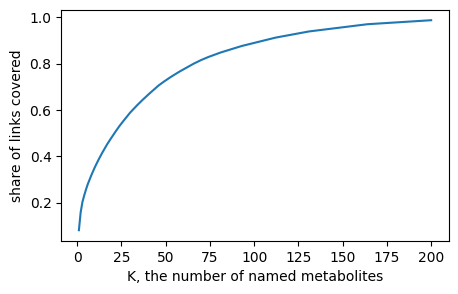

227 metabolites in all; the top 22 cover 50% of the links and the top 55 cover 75%


,K,cells in P(L|Z),links on named metabolites,links per cell
0,5,4194,535,0.128
1,20,14679,1016,0.069
2,50,35649,1518,0.043
3,100,70599,1856,0.026


In [10]:
link_counts = dm.target.value_counts()                 # links per metabolite, most linked first (dm is built in the setup)
coverage = np.cumsum(link_counts.values) / link_counts.sum()    # share of all disease-metabolite links covered by the top K

plt.figure(figsize=(5, 3))
plt.plot(np.arange(1, 201), coverage[:200])
plt.xlabel("K, the number of named metabolites"); plt.ylabel("share of links covered")
plt.show()

K_for_half = int(np.argmax(coverage >= 0.5)) + 1                 # smallest K that covers at least half of the links
K_for_three_quarters = int(np.argmax(coverage >= 0.75)) + 1
print(f"{len(link_counts)} metabolites in all; the top {K_for_half} cover 50% of the links and the top {K_for_three_quarters} cover 75%")

rows = []
for K_try in (5, 20, 50, 100):
    cells = nZ * (K_try + 1)                             # size of P(L|Z) when there are K_try named metabolites plus 'other'
    covered = coverage[K_try - 1] * link_counts.sum()    # links that fall on a named metabolite
    rows.append((K_try, cells, int(covered), covered / cells))
display(pd.DataFrame(rows, columns=["K", "cells in P(L|Z)", "links on named metabolites", "links per cell"]).round(3))

**Discussion.** There are 227 metabolites with at least one disease link in the universe, but they are very unevenly used: the top 22 account for half of the links, and the top 55 for three quarters. The curve rises quickly at first and then flattens, so the long tail of rare metabolites contributes little. In the table, the number of links per cell of $P(L\vert Z)$ falls from 0.13 at $K=5$ to 0.03 at $K=100$. With $K=20$ (the value of the main notebook) the table has about 14,700 cells for about 1,000 links, 0.07 links per cell, so the great majority of the cells are estimated from *no* data and rely entirely on smoothing. A reasonable choice is $K$ between 20 and 55: it covers around half to three quarters of the links, and keeps the table small. There is no right answer, and the point is to *justify* it: a larger $K$ keeps more of the data, a smaller one makes each state better determined, and neither can be judged without looking at how each is used downstream.

**Leakage and cold start.** If each link is withheld independently with probability 0.2, a disease with two links loses both with probability $0.2^2=0.04$, and a disease with five loses all of them with probability $0.2^5=0.00032$. We therefore expect $\sum_z0.2^{k_z}$ diseases to have no training link at all.

In [11]:
# Expected number of diseases whose links are ALL withheld, if each link is withheld independently with probability 0.2
links_per_disease = np.bincount(pairs[:, 1], minlength=nZ)         # links per disease in the whole universe (before withholding)
expected_empty = (0.2 ** links_per_disease).sum()

# The actual number, from the training count matrix
actual_empty = int((np.asarray(CZG.sum(axis=1)).ravel() == 0).sum())
print(f"expected diseases with no training link: {expected_empty:.1f}   actual: {actual_empty}")

expected diseases with no training link: 8.9   actual: 9


**Discussion.** We expect 8.9 diseases with no training link and find 9, so the independent-withholding model describes the split very well. The numbers are small (9 of 699), but they matter: those diseases are in the network (they have a smoothed marginal $P(Z)$, and the neighbour genes still supply $P(Z\vert n)$ for them), but the gene's *own* evidence is missing for every gene that was linked to them. A disease with no training link is still a legitimate *query*: $P(G\vert Z=z)\propto P(G)P(z\vert G)$ can be computed, and only the neighbour evidence and the prior act. But there is nothing to *test* the answer against, since every link of that disease is in the test set. This is the cold-start problem of the main notebook, seen from the disease side. It is also the reason for the rule in the main notebook that a disease must have at least two links to enter the universe: it guarantees that a disease cannot lose its only link.

## 3. Choosing the smoothing constants without peeking

The cell below splits the training links into a fitting part (80%) and a validation part (20%), and defines `fit_and_evaluate`, which builds the network from the fitting links only and ranks the validation links. The links in the fitting part count as known. The withheld test links are never used.

In [12]:
# Split the TRAINING links into a fitting part (80%) and a validation part (20%). The withheld test links are not touched.
rng = np.random.default_rng(SEED + 1)
perm = rng.permutation(len(train))
n_val = int(0.2 * len(train))
val_pairs, fit_pairs = train[perm[:n_val]], train[perm[n_val:]]

def fit_and_evaluate(fit_pairs, eval_pairs, lam, b):
    """Build the network from fit_pairs only, and rank the links in eval_pairs. Links in fit_pairs count as already known."""
    CZ = sp.csr_matrix((np.ones(len(fit_pairs)), (fit_pairs[:, 1], fit_pairs[:, 0])), shape=(nZ, nG))
    m = build_model(CZ, NB, CLZ, lam=lam, b=b)
    return rank_metrics(m["PG"][None, :] * m["PZ_G"], eval_pairs, known_mat=CZ.toarray() > 0)

We now evaluate a grid of $(\lambda,b)$ pairs on the **validation** links, and keep the pair with the best MRR.

In [13]:
rows = {}
for lam in (0.0, 0.1, 0.5, 0.9):
    for b in (0.1, 1.0, 10.0, 100.0):
        rows[(lam, b)] = fit_and_evaluate(fit_pairs, val_pairs, lam, b)
sweep = pd.DataFrame(rows).T
sweep.index.names = ["lambda", "b"]
display(sweep.round(3))

best_lam, best_b = sweep["MRR"].idxmax()
print(f"best on the validation links (by MRR): lambda = {best_lam}, b = {best_b}")

MRR  Hits@10  Hits@100  median rank
lambda b                                           
0.0    0.1    0.012    0.021     0.029       1375.5
       1.0    0.012    0.021     0.030       1375.5
       10.0   0.011    0.021     0.033       1375.5
       100.0  0.010    0.020     0.040       1375.5
0.1    0.1    0.045    0.099     0.330        450.0
       1.0    0.049    0.107     0.348        424.0
       10.0   0.054    0.116     0.380        333.0
       100.0  0.062    0.139     0.380        331.5
0.5    0.1    0.050    0.107     0.354        395.0
       1.0    0.054    0.119     0.372        288.5
       10.0   0.061    0.131     0.386        218.0
       100.0  0.063    0.145     0.390        216.5
0.9    0.1    0.049    0.105     0.352        395.0
       1.0    0.052    0.119     0.368        294.5
       10.0   0.060    0.128     0.385        227.0
       100.0  0.063    0.144     0.388        218.0

best on the validation links (by MRR): lambda = 0.5, b = 100.0


**Discussion of the sweep.** Two features stand out. First, $\lambda=0$ is far worse than every other value: with $\lambda=0$ a gene that has training links uses only those links, so for any disease *outside* them its likelihood is exactly zero, and all of those diseases (nearly all of them) tie. The median rank of 1,375 shows this: it is the middle of the list, because ranking among ties is arbitrary. The neighbour evidence is what lets the model rank anything beyond a gene's known links. Second, among the other values the differences are modest, and the strength $b$ matters more than $\lambda$: larger $b$ shrinks the neighbours' distributions more strongly towards the overall $P(Z)$, and that helps. The best pair on the validation links is $\lambda=0.5$ and $b=100$, which is at the edge of the grid.

Now we refit on **all** of the training links and evaluate once on the withheld test links.

In [14]:
# Now refit on ALL the training links and evaluate once on the withheld test links
final = pd.DataFrame({"default (lambda=0.5, b=1)": fit_and_evaluate(train, held, 0.5, 1.0),
                      f"chosen (lambda={best_lam}, b={best_b})": fit_and_evaluate(train, held, best_lam, best_b)}).T
display(final.round(3))

,MRR,Hits@10,Hits@100,median rank
"default (lambda=0.5, b=1)",0.067,0.139,0.378,248.25
"chosen (lambda=0.5, b=100.0)",0.077,0.156,0.411,179.00


**Discussion.**

1. The validation links must come from the *training* links because the withheld links must stay untouched until the final evaluation; otherwise the choice of constants leaks information from the test set. The fitting part is smaller than the whole training set because the validation links have to be removed from it. This is why the validation scores in the sweep (for example the best MRR of 0.063) are lower than the test scores in the final table (0.077): a model fitted to 80% of the training links knows less than one fitted to all of them, and the validation links have different difficulty from the test links.
2. See the discussion of the sweep above: with $\lambda=0$ the likelihood is zero for every disease that is not among the gene's own training links.
3. The best $b$ is at the edge of the grid, so the true optimum may be larger. The next step is to extend the grid, for example to $b=1000$ and $10^4$, and repeat the validation, stopping when the best value is in the interior. (At very large $b$ the neighbours' distributions collapse to $P(Z)$ and the neighbour evidence is lost, so there is an optimum.)
4. The tuned network has MRR 0.077, Hits@10 0.156 and Hits@100 0.411, against 0.066, 0.136 and 0.382 for the prior alone (main notebook). So, with properly chosen constants, the network does better than the popularity baseline, whereas with the default constants it only matched it. The comparison is fair, because the constants were chosen on validation links and the test links were used once; but the prior-only baseline has no constants to tune, so remember that the tuned network had more freedom. A single run with one random split is also a limited basis for a claim: with more time one would repeat the split with several seeds and report the spread.

## 4. Conditional independence by marginalisation

The cell below builds a sub-universe of 12 genes, 8 diseases and 4 metabolites, chosen so that it contains gene–gene links, and the joint distribution $P(G,N,Z,L)$ as an array `J` indexed `[g, n, z, l]`.

In [15]:
# A small universe: 12 genes, 8 diseases and 4 metabolites, small enough to build the full joint distribution.
rng = np.random.default_rng(0)
usable = np.flatnonzero(model["d"] > 0)                               # genes with training links
hub = usable[np.argmax(model["deg"][usable])]                         # start from the gene with most neighbours,
nbrs = [n for n in NB[:, [hub]].nonzero()[0] if model["d"][n] > 0]    # so that the sub-universe contains gene-gene links
extra = [g for g in rng.permutation(usable) if g != hub and g not in nbrs]
gs = np.sort(np.array(([hub] + nbrs + extra)[:12]))
zs = np.sort(np.argsort(-np.asarray(CZG[:, gs].sum(axis=1)).ravel())[:8])   # the 8 diseases with most links to these genes
ls = np.arange(4)
toy = build_model(CZG[zs][:, gs], NB[gs][:, gs], CLZ[ls][:, zs])

def dense_joint(m):
    """P(G,N,Z,L) = P(G) P(N|G) P(Z|G,N) P(L|Z) as a dense 4-D array, indexed [g, n, z, l]."""
    PN_G = m["PN_G"].toarray()
    PN_G[:, m["deg"] == 0] = m["PN"][:, None]
    PZ_GN = ((1 - m["lam_g"])[None, :, None] * m["own"][:, :, None] + m["lam_g"][None, :, None] * m["PZ_N"][:, None, :])
    return np.einsum("g,ng,zgn,lz->gnzl", m["PG"], PN_G, PZ_GN, m["PL_Z"])

J = dense_joint(toy)
print("shape of the joint [g, n, z, l]:", J.shape, "  sums to", J.sum().round(10))

shape of the joint [g, n, z, l]: (12, 12, 8, 4)   sums to 1.0


Marginalising a variable means summing over its axis, and conditioning means dividing by the sum over the remaining variables. In each case we print the largest absolute difference between the two sides of the equation that the DAG says should hold (or not hold).

In [16]:
# P(G, Z): sum out N (axis 1) and L (axis 3)
PGZ = J.sum(axis=(1, 3))
PG_given_Z = PGZ / PGZ.sum(axis=0, keepdims=True)                   # column z is P(G | Z=z)

# P(G, Z, L): sum out N only; then condition on Z=z and L=l
PGZL = J.sum(axis=1)
z, l = 2, 1
PG_given_ZL = PGZL[:, z, l] / PGZL[:, z, l].sum()
print("max |P(G|Z=z,L=l) - P(G|Z=z)| =", np.abs(PG_given_ZL - PG_given_Z[:, z]).max().round(12))

# P(G | L=l): sum out Z as well
PGL = PGZL.sum(axis=1)                                              # [g, l]
PG_given_L = PGL[:, l] / PGL[:, l].sum()
PG_marginal = J.sum(axis=(1, 2, 3))
print("max |P(G|L=l) - P(G)|         =", np.abs(PG_given_L - PG_marginal).max().round(6))

# G and N: is P(G,N) = P(G) P(N)?
PGN = J.sum(axis=(2, 3))
PN_marginal = PGN.sum(axis=0)
print("max |P(G,N) - P(G)P(N)|       =", np.abs(PGN - np.outer(PG_marginal, PN_marginal)).max().round(6))

# L and N, given Z (N is not a parent of L, but it is a parent of Z)
PNZL = J.sum(axis=0)                                                # [n, z, l]
PNL_given_Z = PNZL[:, z, :] / PNZL[:, z, :].sum()
print("max |P(N,L|Z=z) - P(N|Z=z)P(L|Z=z)| =", np.abs(PNL_given_Z - np.outer(PNL_given_Z.sum(axis=1), PNL_given_Z.sum(axis=0))).max().round(12))

max |P(G|Z=z,L=l) - P(G|Z=z)| = 0.0
max |P(G|L=l) - P(G)|         = 0.002737
max |P(G,N) - P(G)P(N)|       = 0.1152
max |P(N,L|Z=z) - P(N|Z=z)P(L|Z=z)| = 0.0


**Discussion.**

1. **Zero:** $P(G\vert Z=z,L=l)=P(G\vert Z=z)$, and $P(N,L\vert Z=z)=P(N\vert Z=z)P(L\vert Z=z)$. **Not zero:** $P(G\vert L=l)\neq P(G)$, and $P(G,N)\neq P(G)P(N)$. The first zero is the independence that the structure asserts: $L$ is a child of $Z$ only, so once $Z$ is observed, $L$ carries no further information about $G$ (the paths $G\to Z\to L$ and $G\to N\to Z\to L$ both pass through $Z$ and are blocked by it). The second is the same fact for $N$: both of its paths to $L$ run through $Z$. In contrast, *without* observing $Z$, the chain $G\to Z\to L$ is open, so $L$ tells us something about $G$. And $G$ and $N$ are dependent by construction, since $N$ is generated from $G$.
2. A small number does not mean independence. The difference of about 0.003 is small because there are only four metabolites in this sub-universe, and the metabolites of a disease depend only weakly on which genes it has, but it is not zero, and in exact arithmetic the structure says that it should not be. Independence would give zero to rounding error, as in the first and last comparisons (the output shows exactly 0).
3. With an edge $G\to L$, $L$ would depend on both $G$ and $Z$, so the independence of $L$ and $G$ given $Z$ would be lost, and so would the first result. The CPT $P(L\vert Z,G)$ would have $\vert Z\vert\times\vert G\vert\times(\vert L\vert-1)$ free parameters. For the full network of the main notebook ($\vert Z\vert=699$, $\vert G\vert=2{,}324$, $\vert L\vert=21$) that is about 32 million parameters, in place of the 14,000 or so of $P(L\vert Z)$, estimated from the same 1,300 links. So the edge would be impossible to estimate without a smoothing scheme as elaborate as the one for $P(Z\vert G,N)$.

## 5. Explaining a recommendation with SPARQL

**a) The most frequent relations.** In the query we restrict `?rel` to object properties with `?rel a owl:ObjectProperty`, group by relation and count.

In [17]:
query = """
SELECT ?rel (COUNT(*) AS ?n) WHERE {
    ?g a h:Gene .  ?d a h:Disease .
    ?g ?rel ?d .   ?rel a owl:ObjectProperty
} GROUP BY ?rel ORDER BY DESC(?n) LIMIT 5
"""
rows = sparql(query)
display(pd.DataFrame([(r.name, n) for r, n in rows], columns=["relation", "links"]))

,relation,links
0,associated,1852
1,involved,299
2,include,294
3,play,236
4,increase,210


The relation "associated" dominates (1,852 of the gene–disease links in this direction), followed by "involved", "include", "play" and "increase", which are weaker and more varied. "Associated" says only that the text mentions the two together; "increase" says something much more specific. When we collapsed everything to "linked", we gave all of these the same weight.

**b) Path instances.** The function `relations_between` looks up the relation names that join two nodes. It uses the full IRI of each node (safe for names that contain hyphens), a `UNION` for the two directions, and `BIND` to record the direction.

In [18]:
def iri(name):
    """The full IRI of a node, which is safe to use in a query even if the name contains a hyphen or a dot."""
    return "<" + onto.base_iri + name + ">"

def relations_between(a, b):
    """The relation names that link node a to node b, in either direction, from the graph (via SPARQL)."""
    rows = sparql(f"""SELECT ?rel ?direction WHERE {{
        {{ {iri(a)} ?rel {iri(b)} . BIND("->" AS ?direction) }} UNION {{ {iri(b)} ?rel {iri(a)} . BIND("<-" AS ?direction) }}
        ?rel a owl:ObjectProperty }}""")
    return sorted(f"{r.name} ({d})" for r, d in rows)

In [19]:
# The illustrative disease from the main notebook: few training links, at least one withheld link
cands = [z for z in held_by_disease if known[z].sum() <= 3 and len(held_by_disease[z]) >= 1]
z_demo = sorted(cands, key=lambda z: (-len(held_by_disease[z]), diseases[z]))[0]

def path_instances(z, g):
    """All paths  gene g - neighbour n - disease z  where the n-z link is a TRAINING link, with the relation names on each edge."""
    rows = []
    for n in NB[:, [g]].nonzero()[0]:
        if known[z, n]:                                       # n has a training link to z
            rows.append({"neighbour n": genes[n],
                         "weight": model["lam_g"][g] * model["PN_G"][n, g] * model["PZ_N"][z, n],
                         "relations g-n": ", ".join(relations_between(genes[g], genes[n])),
                         "relations n-z": ", ".join(relations_between(genes[n], diseases[z]))})
    return pd.DataFrame(rows).sort_values("weight", ascending=False)

rec = recommend(z_demo)
g_rec = genes.index(rec.gene[0])
print(f"Recommendation for {diseases[z_demo]}: {genes[g_rec]}")
display(path_instances(z_demo, g_rec))

Recommendation for Aging_Premature: BDNF


,neighbour n,weight,relations g-n,relations n-z
0,ERCC6,0.00481,"compensate (->), control (->)","caused (<-), played (->)"


**Discussion.**

1. The recommendation for premature ageing is BDNF, and the only neighbour that supports it is ERCC6, a gene that is linked to the disease in the *training* graph. The relation names on the edges are "compensate" and "control" between BDNF and ERCC6, and "caused" and "played" between ERCC6 and the disease. These are specific verbs, so they say more than mere co-mention: they suggest that BDNF may modulate the pathway of a known causal gene. Notice also that the other neighbours of BDNF do not appear in the table at all, because they have no training link to the disease. Had we collapsed to a single relation *before* looking, we would have lost this information. A good report keeps the relation names in the final explanation even when the model ignores them.
2. For example, ERCC8 is a withheld gene for this disease, and it is the *second* recommendation in the main notebook. Whether a withheld link has a supporting path in the training graph depends on the particular link. A link with no such path (no neighbour that is linked to the disease) can only be recovered through the prior and the cold-start behaviour, so the network cannot be expected to find it. Counting how many of the withheld links have *any* supporting path is a useful upper bound on what a path-based method can achieve, and it is a number that should accompany any evaluation.
3. The probability is a number that cannot be checked. A list of paths can: a reader can look up each relation in the literature, see which of them are specific and which merely statistical, and decide whether the argument is plausible. A probability tells us how the model ranks the candidates; a path tells us why.